# Delivery Route Optimisation Using ILP and SA

IT5082 Optimization Methods

**Problem:**  Capacitated Vehicle Routing Problem (CVRP) <br>
**Exact method:** ILP <br>
**Heuristic:**  Simulated Annealing (SA) <br>
**Data:**  CVRPLIB benchmarks and the Amazon Last Mile 2021 routes<br>
**M L I U Meegahawala (MS26903538)  / M T M Ibjas (MS25942248)**

## Setup
Install the packages from requirements.txt

In [1]:
import itertools, json, math, os, random, time
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import milp, linprog, LinearConstraint, Bounds
from scipy.sparse import coo_matrix
import vrplib

# numba speedup the  SA decoder
try:
    from numba import njit
except ImportError:
    def njit(*args, **kwargs):
        return args[0] if args and callable(args[0]) else (lambda f: f)


SEED = 42
CONFIG = dict(
    exact_time_limit = 120,    # seconds per ILP solve
    exact_max_n      = 45,     # largest instance we try with the ILP
    n_seeds          = 10,     # SA runs per instance
    sa_iters_per_n   = 1500,   # SA iterations = this x number of customers
)

def sa_budget(inst):
    """SA iterations for an instance. The same for every seed, so the comparison is fair."""
    return CONFIG["sa_iters_per_n"] * inst["n"]


# Folders: raw input files, saved instances, figures. Created if they do not exist yet.
RAW, INST, FIG = Path("data/raw"), Path("data/instances"), Path("results/figures")
for p in (RAW, INST, FIG, Path("results")):
    p.mkdir(parents=True, exist_ok=True)

# Plot style for every figure: default size, light grid, no top and right border lines
plt.rcParams.update({"figure.figsize": (7, 4.5), "axes.grid": True, "axes.spines.top": False, "axes.spines.right": False})

# Fixed random seeds, so a re-run gives the same numbers
random.seed(SEED)
np.random.seed(SEED)

print("Config:", CONFIG)

Config: {'exact_time_limit': 120, 'exact_max_n': 45, 'n_seeds': 10, 'sa_iters_per_n': 1500}


## Load the CVRPLIB instances
CVRPLIB gives a proven optimal cost for each instance. We use it to check our ILP and to measure how far SA is from the best answer. <br>The `.vrp` files are added to `data/raw/.

In [2]:
CVRPLIB_OPTIMA = {                      # proven optimal costs, published on CVRPLIB
    "P-n16-k8": 450, "E-n22-k4": 375, "A-n32-k5": 784,
    "A-n33-k5": 661, "A-n60-k9": 1354, "A-n80-k10": 1763,
}

def find_instances():
    """Return the CVRPLIB instances that have a .vrp file in data/raw/."""
    found = [n for n in CVRPLIB_OPTIMA if (RAW / f"{n}.vrp").exists()]
    print(f"found {len(found)} instance files in {RAW}/")
    return found

## Convert to common instance format
ILP and SA read the same input. instance is a plain Python dict.
<br>Distances use CVRPLIB's straight-line distance rounded to the nearest integer.(euclidean_matrix)
<br>The depot is node `0`.

In [3]:
def euclidean_matrix(coords):
    """Distance between every pair of points, rounded to the nearest integer (CVRPLIB rule)."""
    pts = np.asarray(coords, dtype=float)
    d = np.sqrt(((pts[:, None, :] - pts[None, :, :]) ** 2).sum(-1))   # straight-line distances
    return np.rint(d).astype(int)


def parse_cvrplib(path, name=None):
    """Read one .vrp file and return it in to a dict."""
    raw = vrplib.read_instance(str(path))
    name = name or Path(path).stem
    demand = np.asarray(raw["demand"], dtype=int)
    coords = np.asarray(raw["node_coord"], dtype=float)
    return {
        "name": name, "source": "CVRPLIB", "n": len(demand) - 1,     # n = customers without the depot
        "coords": coords.tolist(), "demand": demand.tolist(),
        "capacity": int(raw["capacity"]), "depot": 0,
        "vehicles": int(name.rsplit("-k", 1)[1]),                    # fleet size is in the name A-n32-k5 -> 5
        "dist": euclidean_matrix(coords).tolist(),
        "cost_unit": "distance units", "known_opt": CVRPLIB_OPTIMA.get(name),
    }

def save_instance(inst):
    """Save an instance as JSON in data/instances/."""
    p = INST / f"{inst['name']}.json"
    p.write_text(json.dumps(inst))
    return p

def validate_instance(inst):
    """Valiidate the instances, so a bad instance can be removed"""
    d, D = np.asarray(inst["demand"]), np.asarray(inst["dist"])
    nm = inst["name"]
    assert inst["depot"] == 0, f"{nm}: depot must be node 0"
    assert D.shape == (len(d), len(d)), f"{nm}: matrix shape {D.shape} != {len(d)}"
    assert d[0] == 0, f"{nm}: depot has non-zero demand"
    assert d.max() <= inst["capacity"], f"{nm}: a single demand exceeds capacity"
    assert (np.diag(D) == 0).all() and (D >= 0).all(), f"{nm}: bad cost matrix"
    need = math.ceil(d.sum() / inst["capacity"])                     # fewest vehicles that could carry all demand
    assert need <= inst["vehicles"], f"{nm}: needs {need} vehicles but fleet is {inst['vehicles']}"
    return True


def instance_summary(instances):
    """summary table for report"""
    rows = []
    for i in instances:
        d = np.asarray(i["demand"])
        rows.append({"name": i["name"], "source": i["source"], "n": i["n"], "capacity": i["capacity"],
                     "total_demand": int(d.sum()), "vehicles": i["vehicles"],
                     "min_vehicles": math.ceil(d.sum() / i["capacity"]),
                     "tightness": round(d.sum() / (i["vehicles"] * i["capacity"]), 3),   # 1.0 = fleet is completely full
                     "known_opt": i["known_opt"], "cost_unit": i["cost_unit"]})
    return pd.DataFrame(rows).sort_values(["source", "n"]).reset_index(drop=True)


## Amazon Last Mile data`
Real delivery routes from the Amazon Last Mile Routing Challenge 2021.

<b>We use small subset from one station, saved in data/raw/amazon_subset.json

In [4]:
AMZ_SUBSET = RAW / "amazon_subset.json"      # small file cut from the full Amazon data (see tools/extract_amazon_subset.py for extraction script)
AMAZON = json.loads(AMZ_SUBSET.read_text())
print(f"Amazon subset: station {AMAZON['station']}, {len(AMAZON['route_data'])} routes")

Amazon subset: station DLA3, 12 routes


## Build CVRP instances from one Amazon route
- **Depot:** delivery station.
- **Customers:** fixed random sample of the stops
- **Demand:** package volume at the stop, in litres.
- **Cost:** real travel time in seconds. It is asymmetric (A to B is not B to A).
- **Capacity:** The real van carries the whole route, so we use several smaller vans instead. Capacity = total demand / (vehicles × fill).

In [5]:
def amazon_route_to_instance(A, rid, n_stops, fleet=4, fill=0.85, seed=SEED):
    """Turn one Amazon route into a CVRP instance with n_stops customers."""
    rd, pk, tt = A["route_data"][rid], A["package_data"][rid], A["travel_times"][rid]
    stops = rd["stops"]

    # Depot = the station. Customers = delivery stops that have packages.
    depot_id = next(s for s, v in stops.items() if v.get("type") == "Station")
    customers = [s for s, v in stops.items() if v.get("type") == "Dropoff" and s in pk]

    # Fixed-seed shuffle, so smaller instances are always inside the bigger ones.
    random.Random(seed).shuffle(customers)
    ids = [depot_id] + customers[:n_stops]                      # node 0 = depot

    # Demand of a stop = total volume of its packages, in litres (cm3 / 1000), rounded up, at least 1.
    def volume_l(stop):
        return sum(p["dimensions"]["depth_cm"] * p["dimensions"]["height_cm"] * p["dimensions"]["width_cm"]
                   for p in pk[stop].values()) / 1000.0
    demand = [0] + [max(1, math.ceil(volume_l(s))) for s in ids[1:]]

    # Cost = real travel time in seconds. It is not symmetric: D[a][b] can differ from D[b][a].
    D = np.array([[0 if a == b else round(tt[a][b]) for b in ids] for a in ids])

    # Capacity is our assumption: total demand spread over the fleet, with vans about `fill` (85%) full.
    # max(...) makes sure the biggest single stop still fits in one van.
    capacity = max(math.ceil(sum(demand) / (fleet * fill)), max(demand))

    return {"name": f"AMZ-{rid[-6:]}-n{n_stops}", "source": "Amazon", "n": n_stops,
            "coords": [[stops[s]["lng"], stops[s]["lat"]] for s in ids],
            "demand": demand, "capacity": capacity, "depot": 0, "vehicles": fleet,
            "dist": D.tolist(), "cost_unit": "seconds", "known_opt": None, "route_id": rid}


def build_amazon_instances(A, sizes=(10, 15, 20, 30, 50, 80), fleet_for=lambda n: max(2, math.ceil(n / 8))):
    """Build one instance per size, all from the same route (the one with the most deliveries)."""
    n_drop = lambda r: sum(v.get("type") == "Dropoff" for v in A["route_data"][r]["stops"].values())
    rid = max(A["route_data"], key=n_drop)
    return [amazon_route_to_instance(A, rid, n, fleet=fleet_for(n)) for n in sizes if n <= n_drop(rid)]

## Load, validate and sumamrise
Load all instances and check each one with `validate_instance`. `instance_summary` table summarises every instance.

In [6]:
# 1) CVRPLIB instances: read every .vrp file found in data/raw/
instances = [parse_cvrplib(RAW / f"{nm}.vrp", nm) for nm in find_instances()]

# 2) Amazon instances: build them from the saved subset
instances += build_amazon_instances(AMAZON)

# 3) Check each instance, then save it as JSON in data/instances/
for inst in instances:
    validate_instance(inst)
    save_instance(inst)

by_name = {i["name"]: i for i in instances}      # quick lookup by name
SMOKE = by_name["P-n16-k8"]                      # small instance used for quick demos and checks

reg = instance_summary(instances)           # summary table (Table 1 in the report)
print(f"{len(instances)} instances validated and saved to {INST}/")
reg

found 6 instance files in data/raw/
12 instances validated and saved to data/instances/


,name,source,n,capacity,total_demand,vehicles,min_vehicles,tightness,known_opt,cost_unit
0,AMZ-c6a02b-n10,Amazon,10,127,215,2,2,0.846,NaN,seconds
1,AMZ-c6a02b-n15,Amazon,15,149,252,2,2,0.846,NaN,seconds
2,AMZ-c6a02b-n20,Amazon,20,146,370,3,3,0.845,NaN,seconds
3,AMZ-c6a02b-n30,Amazon,30,187,633,4,4,0.846,NaN,seconds
4,AMZ-c6a02b-n50,Amazon,50,161,957,7,6,0.849,NaN,seconds
5,AMZ-c6a02b-n80,Amazon,80,180,1529,10,9,0.849,NaN,seconds
6,P-n16-k8,CVRPLIB,15,35,246,8,8,0.879,450.0,distance units
7,E-n22-k4,CVRPLIB,21,6000,22500,4,4,0.938,375.0,distance units
8,A-n32-k5,CVRPLIB,31,100,410,5,5,0.820,784.0,distance units
9,A-n33-k5,CVRPLIB,32,100,446,5,5,0.892,661.0,distance units


## Instance analysis
Before running any method we look at the instances to see **what makes them hard**. This is the optimisation equivalent of exploratory data analysis: we check where the stops are, how big the demands are against vehicle capacity, whether the cost matrix is symmetric, and how fast the search space grows.

### Where the stops are
Three CVRPLIB instances and one Amazon instance. Marker size shows demand; the black square is the depot. CVRPLIB customers are spread out, while the Amazon stops sit in a tight cluster with the depot far away.

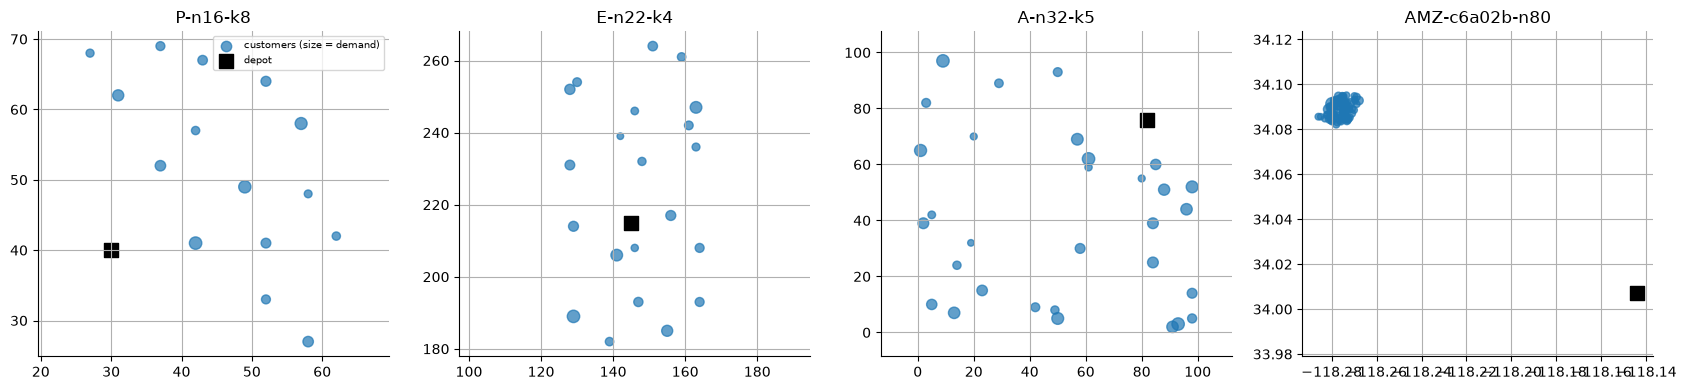

In [7]:
def plot_instance(inst, ax=None, title=None):
    ax = ax or plt.gca()
    xy, d = np.asarray(inst["coords"]), np.asarray(inst["demand"])
    ax.scatter(xy[1:, 0], xy[1:, 1], s=20 + 6 * d[1:] / max(1, d[1:].max()) * 10, alpha=.7, label="customers (size = demand)")
    ax.scatter(*xy[0], marker="s", s=90, c="k", label="depot")
    ax.set_title(title or inst["name"]); ax.set_aspect("equal", "datalim")

pick = [i for i in instances if i["name"] in ("P-n16-k8", "E-n22-k4", "A-n32-k5")] or instances[:3]
amz = [i for i in instances if i["source"] == "Amazon"]
pick = (pick + amz[-1:])[:4]
fig, axs = plt.subplots(1, len(pick), figsize=(4.2 * len(pick), 4))
for a, i in zip(np.atleast_1d(axs), pick): plot_instance(i, a)
np.atleast_1d(axs)[0].legend(fontsize=7, loc="best")
plt.tight_layout(); plt.savefig(FIG / "2_1_instances.png", dpi=150); plt.show()

### Demand distribution and capacity tightness
Left: each customer's demand as a share of vehicle capacity. Right: capacity tightness (total demand / (K x Q)); a value close to 1 means little slack, so the instance is usually harder.

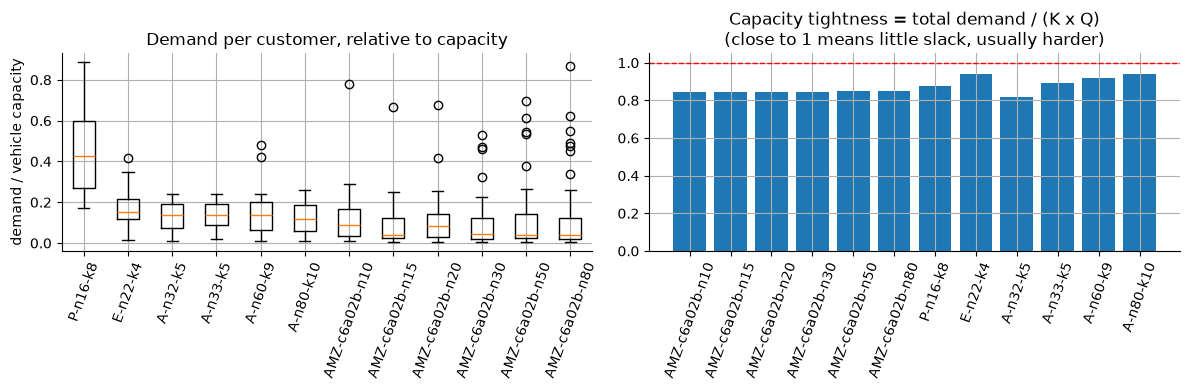

In [8]:
fig, axs = plt.subplots(1, 2, figsize=(12, 4))
data = [np.asarray(i["demand"][1:]) / i["capacity"] for i in instances]
axs[0].boxplot(data); axs[0].set_xticks(range(1, len(instances) + 1)); axs[0].set_xticklabels([i["name"] for i in instances])
axs[0].set_ylabel("demand / vehicle capacity"); axs[0].set_title("Demand per customer, relative to capacity")
axs[0].tick_params(axis="x", rotation=70)
t = reg.set_index("name")["tightness"]
axs[1].bar(range(len(t)), t.values); axs[1].set_xticks(range(len(t))); axs[1].set_xticklabels(t.index, rotation=70)
axs[1].axhline(1, color="r", ls="--", lw=1); axs[1].set_ylim(0, 1.05)
axs[1].set_title("Capacity tightness = total demand / (K x Q)\n(close to 1 means little slack, usually harder)")
plt.tight_layout(); plt.savefig(FIG / "2_2_demand_tightness.png", dpi=150); plt.show()

### Cost matrix: symmetric or not?
CVRPLIB distances are symmetric (Euclidean). The Amazon travel times are **not** (one-way streets, turns, traffic). We measure the share of node pairs whose two directions differ by more than 10%, which justifies a **directed** formulation that uses the full asymmetric matrix.

In [9]:
rows = []
for i in instances:
    D = np.asarray(i["dist"], float); iu = np.triu_indices(len(D), 1)
    a, b = D[iu], D.T[iu]
    rel = np.abs(a - b) / np.maximum(1, (a + b) / 2)
    rows.append({"instance": i["name"], "pairs": len(a), "share_asymmetric_>10%": round(float((rel > .10).mean()), 3),
                 "mean_rel_diff": round(float(rel.mean()), 3)})
sym = pd.DataFrame(rows); sym

,instance,pairs,share_asymmetric_>10%,mean_rel_diff
0,P-n16-k8,120,0.000,0.000
1,E-n22-k4,231,0.000,0.000
2,A-n32-k5,496,0.000,0.000
3,A-n33-k5,528,0.000,0.000
4,A-n60-k9,1770,0.000,0.000
5,A-n80-k10,3160,0.000,0.000
6,AMZ-c6a02b-n10,55,0.309,0.101
7,AMZ-c6a02b-n15,120,0.267,0.087
8,AMZ-c6a02b-n20,210,0.295,0.088
9,AMZ-c6a02b-n30,465,0.327,0.093


### Why we need a heuristic: the size of the problem
For `n` customers the ILP has about `n(n+1)` binary arc variables, but the number of visiting orders is `n!`. The ILP model stays small while the search space explodes, so exact solvers rely on bounding and pruning and a fast heuristic becomes attractive as `n` grows.**

,n customers,binary arc variables n(n+1),visiting orders n!
0,5,30,1.20e+02
1,8,72,4.03e+04
2,10,110,3.63e+06
3,15,240,1.31e+12
4,20,420,2.43e+18
5,30,930,2.65e+32
6,50,2550,3.04e+64
7,80,6480,7.16e+118
8,100,10100,9.33e+157


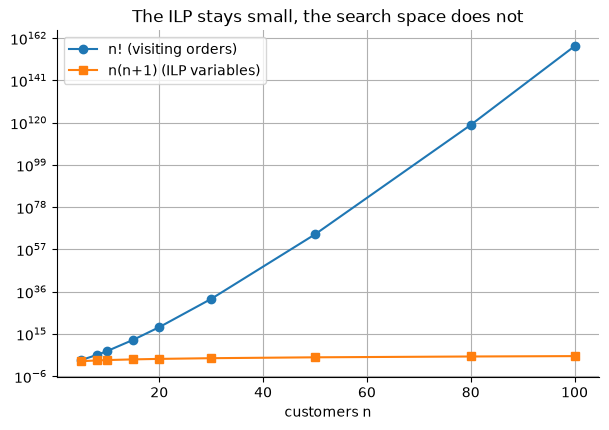

In [10]:
ns = np.array([5, 8, 10, 15, 20, 30, 50, 80, 100])
growth = pd.DataFrame({"n customers": ns, "binary arc variables n(n+1)": ns * (ns + 1),
                       "visiting orders n!": [f"{math.factorial(int(n)):.2e}" for n in ns]})
display(growth)
fig, ax = plt.subplots(); ax.semilogy(ns, [math.factorial(int(n)) for n in ns], "o-", label="n! (visiting orders)")
ax.semilogy(ns, ns * (ns + 1), "s-", label="n(n+1) (ILP variables)"); ax.set_xlabel("customers n"); ax.legend()
ax.set_title("The ILP stays small, the search space does not"); plt.savefig(FIG / "2_5_growth.png", dpi=150); plt.show()